# Pandas: Explode

In [14]:
!pip install datasets

In [15]:
# importing Libraries
import ast
import pandas as pd 
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df=dataset['train'].to_pandas()

# Data Cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)


In [16]:
df_DE= df[df['job_title_short'] == 'Data Engineer'].copy()

In [17]:
df_DE['job_posted_month_no'] = df_DE['job_posted_date'].dt.month
df_DE_explode = df_DE.explode('job_skills')
df_DE_pivot = df_DE_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)
# df_DE_pivot.plot(kind='line')


In [18]:
df_DE_pivot.loc['Total'] = df_DE_pivot.sum()
df_DE_pivot = df_DE_pivot[df_DE_pivot.loc['Total'].sort_values(ascending=False).index]
df_DE_pivot = df_DE_pivot.drop('Total')
df_DE_pivot

job_skills,sql,python,aws,azure,spark,java,kafka,hadoop,scala,databricks,...,shogun,fastify,workfront,dlib,ember.js,homebrew,asp.netcore,linode,chainer,dingtalk
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,12987,12426,6924,7138,6567,4246,3687,3533,3517,3002,...,2,0,0,0,0,0,0,0,0,0
2,9792,9378,5446,5278,4948,3300,2809,2774,2625,2272,...,1,0,0,0,0,0,0,0,0,0
3,9831,9410,5580,5283,4764,3223,2689,2592,2621,2378,...,0,0,0,0,0,0,0,0,0,0
4,8975,8670,5012,4901,4316,2931,2329,2340,2373,2170,...,0,0,0,0,0,3,0,0,1,0
5,8411,8169,4768,4466,3991,2725,2166,2195,2132,2034,...,0,0,0,0,0,0,1,0,0,0
6,9713,9216,5280,5091,4654,3092,2516,2468,2464,2317,...,0,0,1,0,0,0,0,0,0,0
7,9032,8493,5015,4857,4044,2757,2296,2235,2213,2161,...,0,0,2,2,0,0,0,0,0,0
8,9565,9016,5330,5070,4436,2961,2468,2421,2427,2310,...,0,0,1,0,0,0,1,0,0,0
9,8663,8213,4612,4646,3902,2584,2088,2024,2070,2198,...,1,0,0,0,0,0,0,1,0,0


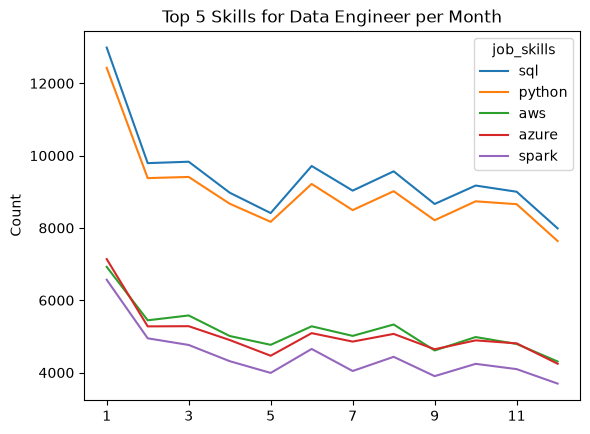

In [19]:
df_DE_pivot.iloc[:, :5].plot(kind="line")
plt.title('Top 5 Skills for Data Engineer per Month')
plt.ylabel('Count')
plt.xlabel("")
plt.show()

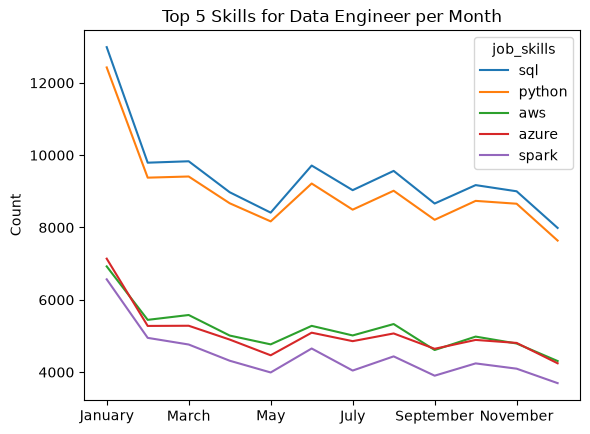

In [20]:
df_DE_pivot = df_DE_pivot.reset_index()

df_DE_pivot['job_posted_month'] = df_DE_pivot['job_posted_month_no'].apply(
    lambda x: pd.to_datetime(str(x), format='%m').strftime('%B')
)

df_DE_pivot = df_DE_pivot.set_index('job_posted_month')
df_DE_pivot = df_DE_pivot.drop(columns='job_posted_month_no')

df_DE_pivot.iloc[:, :5].plot(kind='line')
plt.title('Top 5 Skills for Data Engineer per Month')
plt.ylabel('Count')
plt.xlabel('')
plt.show()